# AeroRUL — Phase 5: Hyperparameter Tuning & Final Model Selection

This notebook provides an interactive, reproducible walkthrough of **Phase 5**:
1. **Critical Preflight**: Official test endpoint feature availability audit (addressing truncated test trajectories).
2. **Stage A — Inner Grouped Cross-Validation**: 3-fold engine-grouped CV optimizing Engine-Macro MAE.
3. **Hyperparameter Optimization**: Bayesian optimization of LightGBM and XGBoost via Optuna.
4. **Baseline & Classical Benchmarks**: Comparing against DummyBaseline, LinearRegression, Ridge, and RandomForest.
5. **RUL Target Cap Sensitivity**: Evaluating caps $\in [\text{None}, 50, 75, 100, 125, 150]$ against uncapped physical truth.
6. **Window Feature Configuration Ablation**: Evaluating single windows ($W=10..75$) vs multi-scale combined windows.
7. **Stage B — Development Validation**: Validating finalists on designated Phase 2 validation partition.
8. **Configuration Freeze**: Saving `final_model_manifest.json` before touching official test labels.
9. **Stage C — Official Test Evaluation**: Evaluating frozen models against official `RUL_FD*.txt` ground truth.

## 1. Environment & Setup

In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import AVAILABLE_SUBSETS, REPORTS_DIR, FIGURES_DIR
from src.metrics import mae, rmse, r2_score, mean_signed_error, nasa_score

PHASE5_DIR = REPORTS_DIR / "phase5"
PHASE5_FIGURES_DIR = PHASE5_DIR / "figures"

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")
print(f"Project root: {PROJECT_ROOT}")
print(f"Phase 5 reports directory: {PHASE5_DIR}")

Project root: C:\Users\himan\OneDrive\Documents\AeroRUL
Phase 5 reports directory: C:\Users\himan\OneDrive\Documents\AeroRUL\reports\phase5


## 2. Critical Preflight: Official Test Feature Availability Audit

In C-MAPSS, test engine trajectories are truncated before failure. Many test engines have fewer than 75 observed cycles at their final recorded point (e.g. min cycle 19 in FD004, 21 in FD002, 31 in FD001). Under standard 75-cycle windowing, these engines would lack feature representation.
AeroRUL implements a **causal partial-history-aware feature mode** that represents 100% of official test engines without looking ahead.

In [2]:
avail_df = pd.read_csv(PHASE5_DIR / "test_endpoint_feature_availability.csv")
print(f"Total test engine audit records: {len(avail_df)}")

# Summary by configuration and dataset
summary = avail_df.groupby(["dataset", "candidate_feature_configuration"])["endpoint_feature_available"].value_counts().unstack().fillna(0)
print("\nEndpoint Availability Summary (True vs False):")
display(summary)

# Feature Configuration Inventory
inv_df = pd.read_csv(PHASE5_DIR / "feature_configuration_inventory.csv")
print("\nCandidate Feature Configurations:")
display(inv_df[["dataset", "feature_configuration", "feature_count", "earliest_usable_cycle_full", "earliest_usable_cycle_partial"]])

Total test engine audit records: 4949

Endpoint Availability Summary (True vs False):


endpoint_feature_available               False  True 
dataset candidate_feature_configuration              
FD001   ALL_WINDOWS                       20.0   80.0
        ALL_WINDOWS_PARTIAL                0.0  100.0
        W10                                0.0  100.0
        W20                                0.0  100.0
        W30                                0.0  100.0
        W50                                7.0   93.0
        W75                               20.0   80.0
FD002   ALL_WINDOWS                       59.0  200.0
        ALL_WINDOWS_PARTIAL                0.0  259.0
        W10                                0.0  259.0
        W20                                0.0  259.0
        W30                                6.0  253.0
        W50                               24.0  235.0
        W75                               59.0  200.0
FD003   ALL_WINDOWS                       11.0   89.0
        ALL_WINDOWS_PARTIAL                0.0  100.0
        W10                                0.0  100.0
        W20                                0.0  100.0
        W30                                0.0  100.0
        W50                                3.0   97.0
        W75                               11.0   89.0
FD004   ALL_WINDOWS                       41.0  207.0
        ALL_WINDOWS_PARTIAL                0.0  248.0
        W10                                0.0  248.0
        W20                                2.0  246.0
        W30                               11.0  237.0
        W50                               20.0  228.0
        W75                               41.0  207.0


Candidate Feature Configurations:


,dataset,feature_configuration,feature_count,earliest_usable_cycle_full,earliest_usable_cycle_partial
0,FD001,ALL_WINDOWS,670,75,1
1,FD001,W10,194,10,1
2,FD001,W20,195,20,1
3,FD001,W30,194,30,1
4,FD001,W50,194,50,1
5,FD001,W75,193,75,1
6,FD002,ALL_WINDOWS,776,75,1
7,FD002,W10,235,10,1
8,FD002,W20,237,20,1
9,FD002,W30,237,30,1


## 3. Stage A: Inner Grouped Cross-Validation Benchmark & Optuna Tuning

The training engines were partitioned using 3-fold `GroupKFold` by engine ID. All preprocessing scalers and cutoff schedules were fitted exclusively on fold-training engines.
The primary optimization metric is **Engine-Macro MAE**.

,dataset,model,engine_macro_mae,pooled_mae,pooled_rmse,nasa_score_mean
0,FD001,DummyBaseline,40.331979,45.596983,58.807823,7.716230e+04
1,FD001,RidgeRegression,21.504220,21.851924,28.801764,9.694929e+01
2,FD001,RandomForest_Fixed,15.914292,16.851206,25.627539,1.014604e+02
3,FD001,LightGBM_Tuned,14.255805,14.958783,23.647053,1.218122e+02
4,FD001,XGBoost_Tuned,14.654432,15.405015,23.947359,1.580062e+02
5,FD002,DummyBaseline,40.131984,45.306799,58.565512,1.107891e+05
6,FD002,RidgeRegression,21.080873,21.476535,29.289646,3.146659e+02
7,FD002,RandomForest_Fixed,17.904917,18.522996,28.086962,5.795352e+02
8,FD002,LightGBM_Tuned,16.897017,17.664129,26.850122,2.281337e+02
9,FD002,XGBoost_Tuned,16.953315,17.767542,26.960108,2.337142e+02


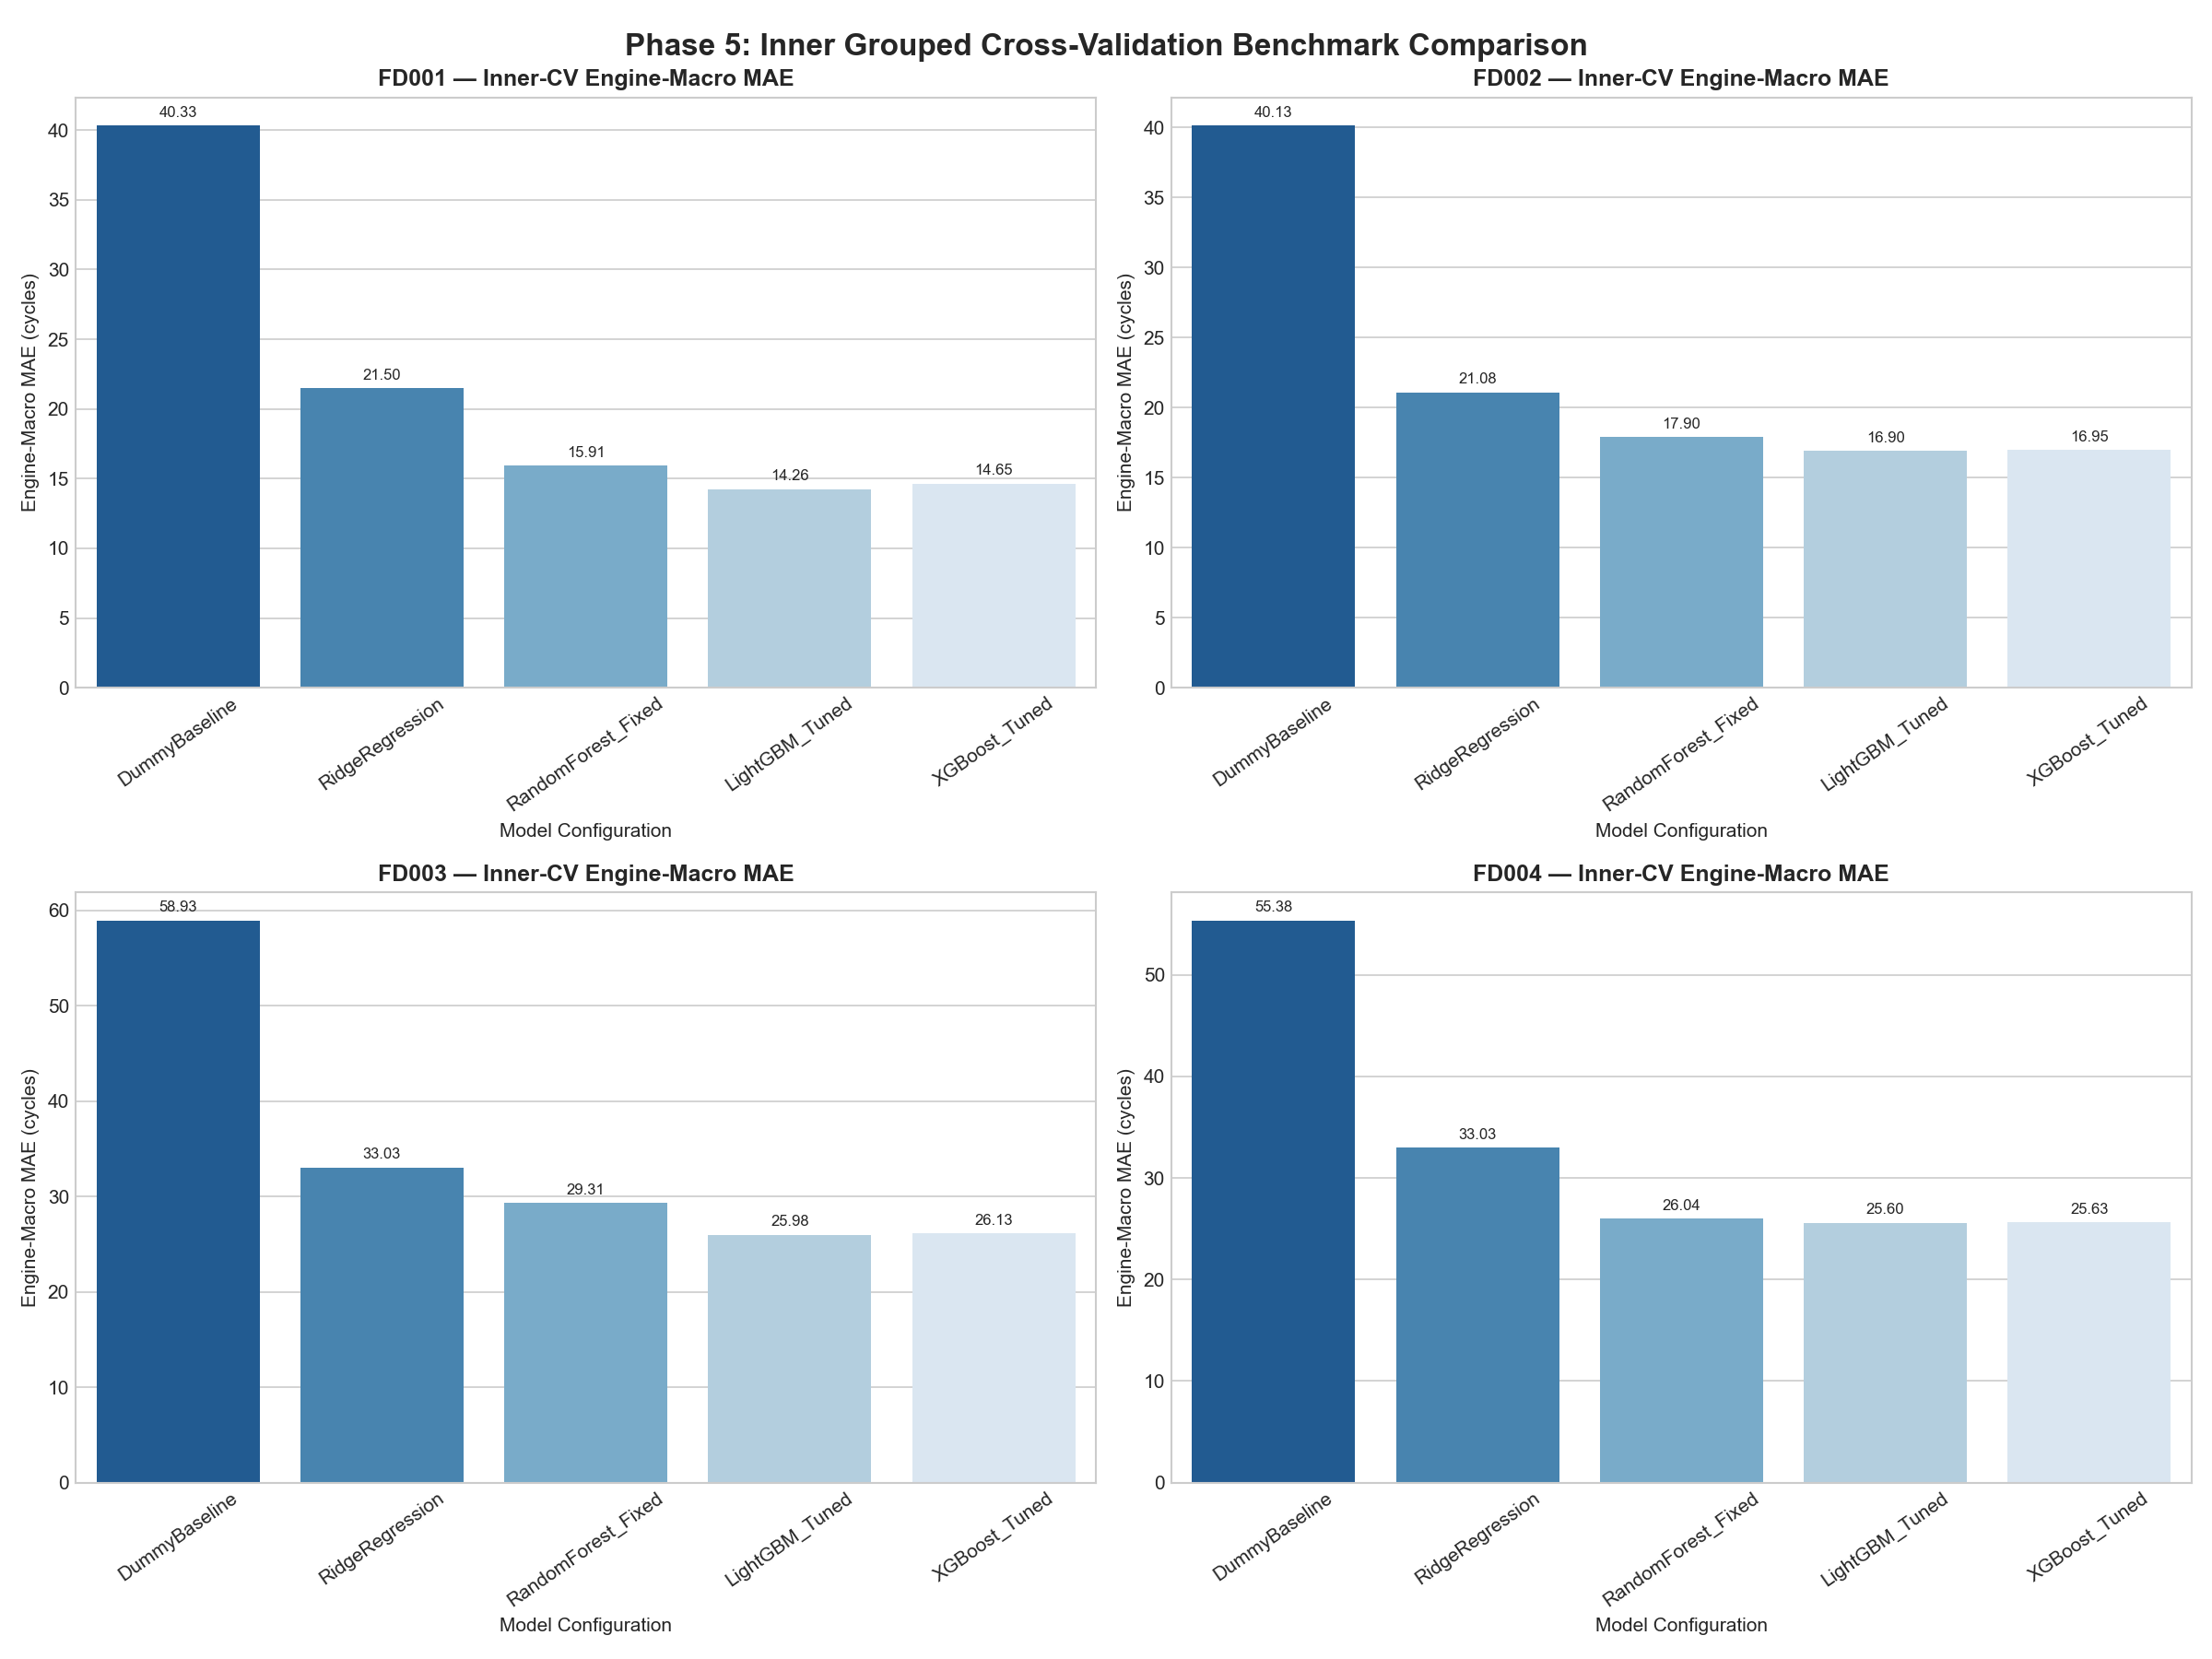

In [3]:
cv_df = pd.read_csv(PHASE5_DIR / "cross_validation_metrics.csv")
display(cv_df[["dataset", "model", "engine_macro_mae", "pooled_mae", "pooled_rmse", "nasa_score_mean"]])

# Display tuning curves
fig_path = PHASE5_FIGURES_DIR / "cv_model_comparison.png"
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

## 4. Optuna Hyperparameter Search Progression

Total Optuna search trials: 100


,dataset,model_family,trial_id,engine_macro_mae,pooled_mae,pooled_rmse,runtime_sec
0,FD001,LightGBM,10,14.255805,14.958783,23.647053,21.43
1,FD001,XGBoost,6,14.654432,15.405015,23.947359,27.96
2,FD002,LightGBM,13,16.897017,17.664129,26.850122,126.88
3,FD002,XGBoost,1,16.953315,17.767542,26.960108,187.54
4,FD003,LightGBM,11,25.983285,28.893737,45.541838,32.46
5,FD003,XGBoost,6,26.130796,29.150891,46.438643,38.60
6,FD004,LightGBM,14,25.599906,26.969885,40.733109,92.41
7,FD004,XGBoost,1,25.625416,27.028383,41.058538,219.81


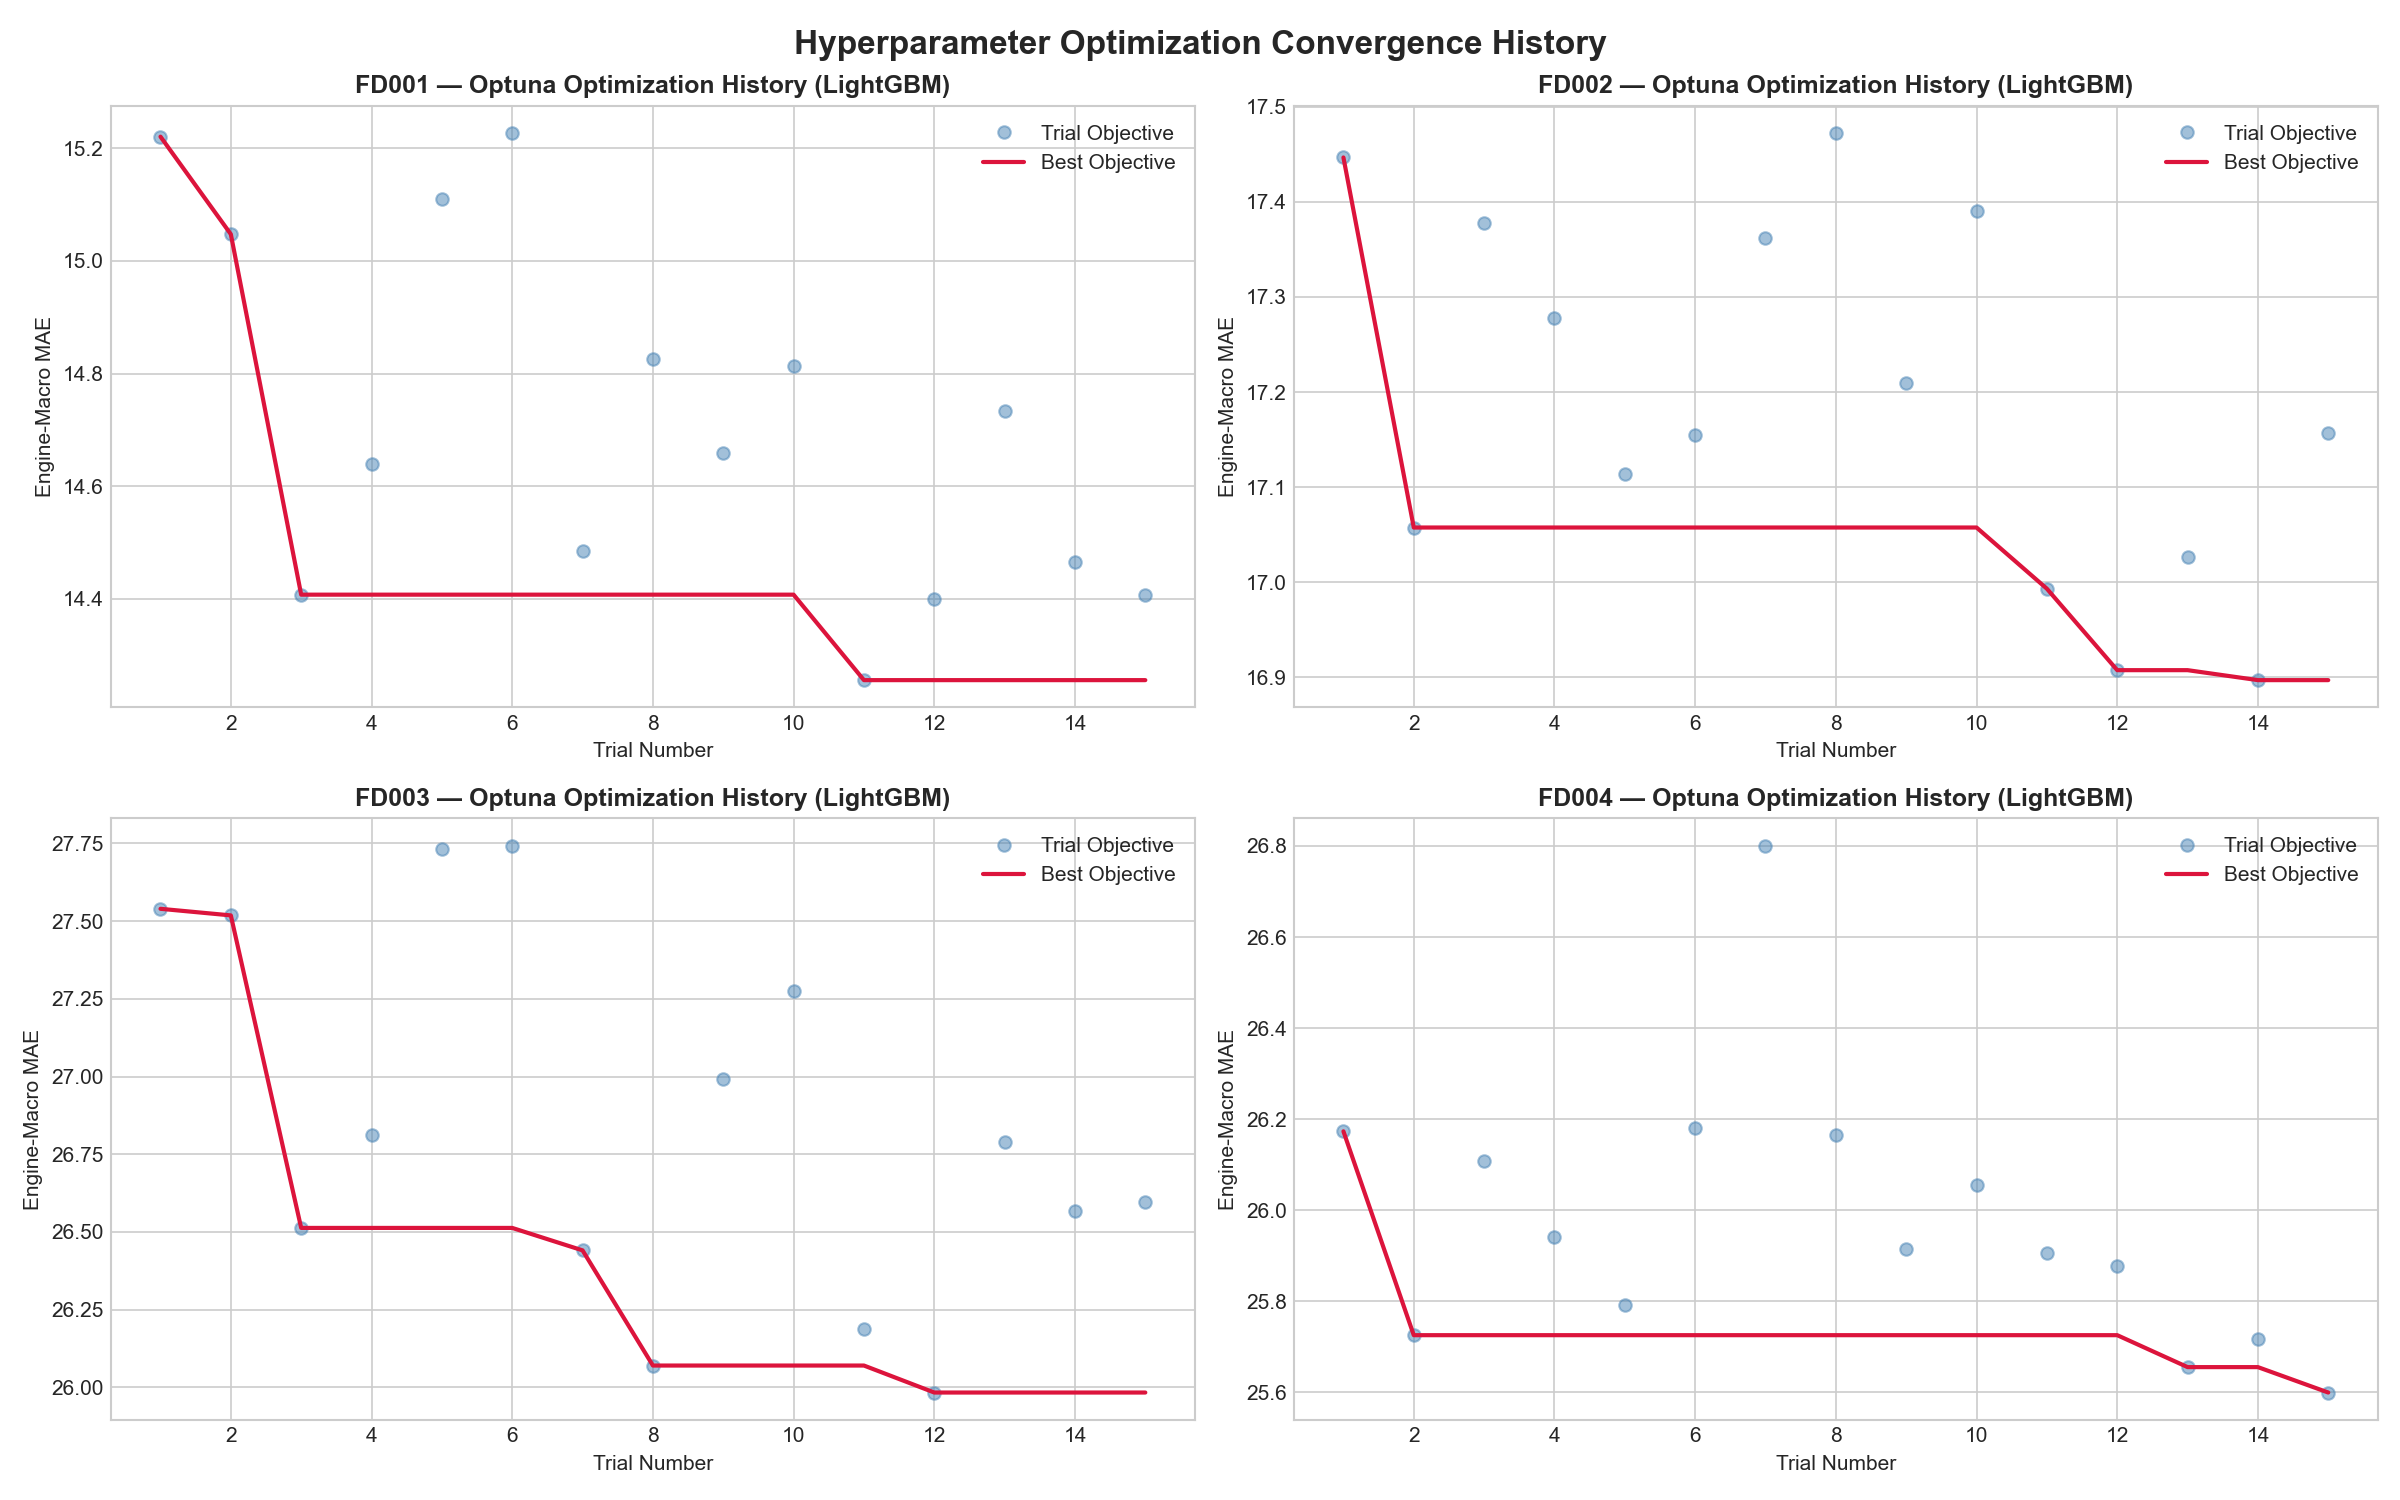

In [4]:
opt_df = pd.read_csv(PHASE5_DIR / "hyperparameter_search_results.csv")
print(f"Total Optuna search trials: {len(opt_df)}")

# Display best trial per model family
best_trials = opt_df.sort_values("engine_macro_mae").groupby(["dataset", "model_family"]).first().reset_index()
display(best_trials[["dataset", "model_family", "trial_id", "engine_macro_mae", "pooled_mae", "pooled_rmse", "runtime_sec"]])

fig_path = PHASE5_FIGURES_DIR / "optuna_tuning_history.png"
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

## 5. RUL Target Cap Sensitivity Analysis

Piecewise linear degradation modeling caps healthy initial RUL. Target caps $\in [\text{None}, 50, 75, 100, 125, 150]$ were evaluated against **UNCAPPED physical ground truth** to quantify generalization fidelity.

,dataset,target_cap,cv_engine_macro_mae,val_engine_macro_mae,val_pooled_rmse,val_nasa_score_sum
0,FD001,NaN,14.255805,11.721586,18.310185,1.242248e+03
1,FD001,50.0,37.950413,34.906803,56.656567,1.635934e+05
2,FD001,75.0,24.519267,22.198323,41.437281,2.437402e+04
3,FD001,100.0,17.106948,16.262726,29.811005,4.373444e+03
4,FD001,125.0,14.347717,13.402619,22.070206,1.184607e+03
5,FD001,150.0,14.083976,12.089520,18.603108,5.988153e+02
6,FD002,NaN,16.897017,16.646810,24.552346,9.459569e+03
7,FD002,50.0,38.527752,33.306307,56.863332,1.762499e+07
8,FD002,75.0,26.047558,21.666730,42.493102,2.576219e+06
9,FD002,100.0,19.416612,16.661106,32.336348,3.968469e+05


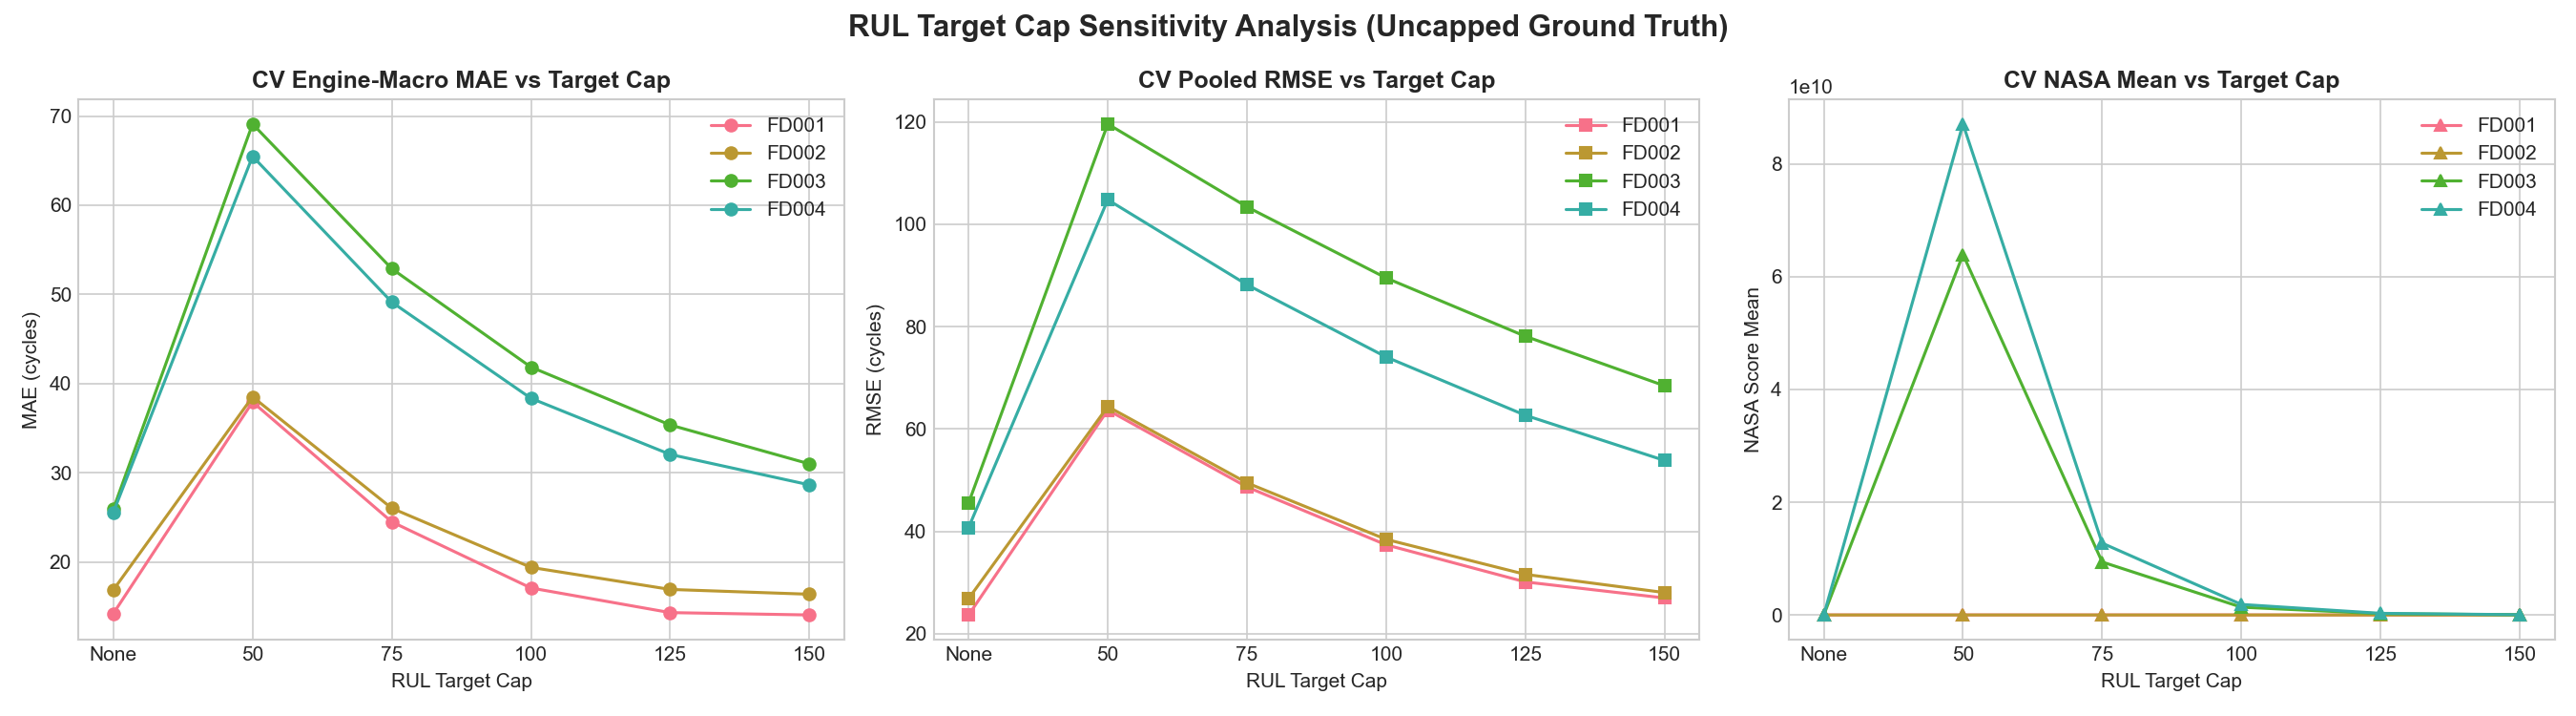

In [5]:
cap_df = pd.read_csv(PHASE5_DIR / "target_cap_sensitivity.csv")
display(cap_df[["dataset", "target_cap", "cv_engine_macro_mae", "val_engine_macro_mae", "val_pooled_rmse", "val_nasa_score_sum"]])

fig_path = PHASE5_FIGURES_DIR / "target_cap_sensitivity.png"
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

## 6. Window Feature Configuration Ablation

Comparing single-scale rolling representations against multi-scale combinations (`ALL_WINDOWS`).

,dataset,window_configuration,feature_count,cv_engine_macro_mae,val_engine_macro_mae,val_pooled_rmse
0,FD001,ALL_WINDOWS,670,14.255805,11.721586,18.310185
1,FD001,W10,194,24.677518,18.667201,25.513356
2,FD001,W20,195,21.606044,15.516012,22.337323
3,FD001,W30,194,19.221930,15.009172,22.822445
4,FD001,W50,194,16.801162,12.728616,19.326598
5,FD001,W75,193,14.573557,11.482084,17.212749
6,FD002,ALL_WINDOWS,776,16.897017,16.646810,24.552346
7,FD002,W10,235,25.638371,23.800003,32.608791
8,FD002,W20,237,24.499977,23.328969,31.626587
9,FD002,W30,237,22.284819,20.284045,28.952004


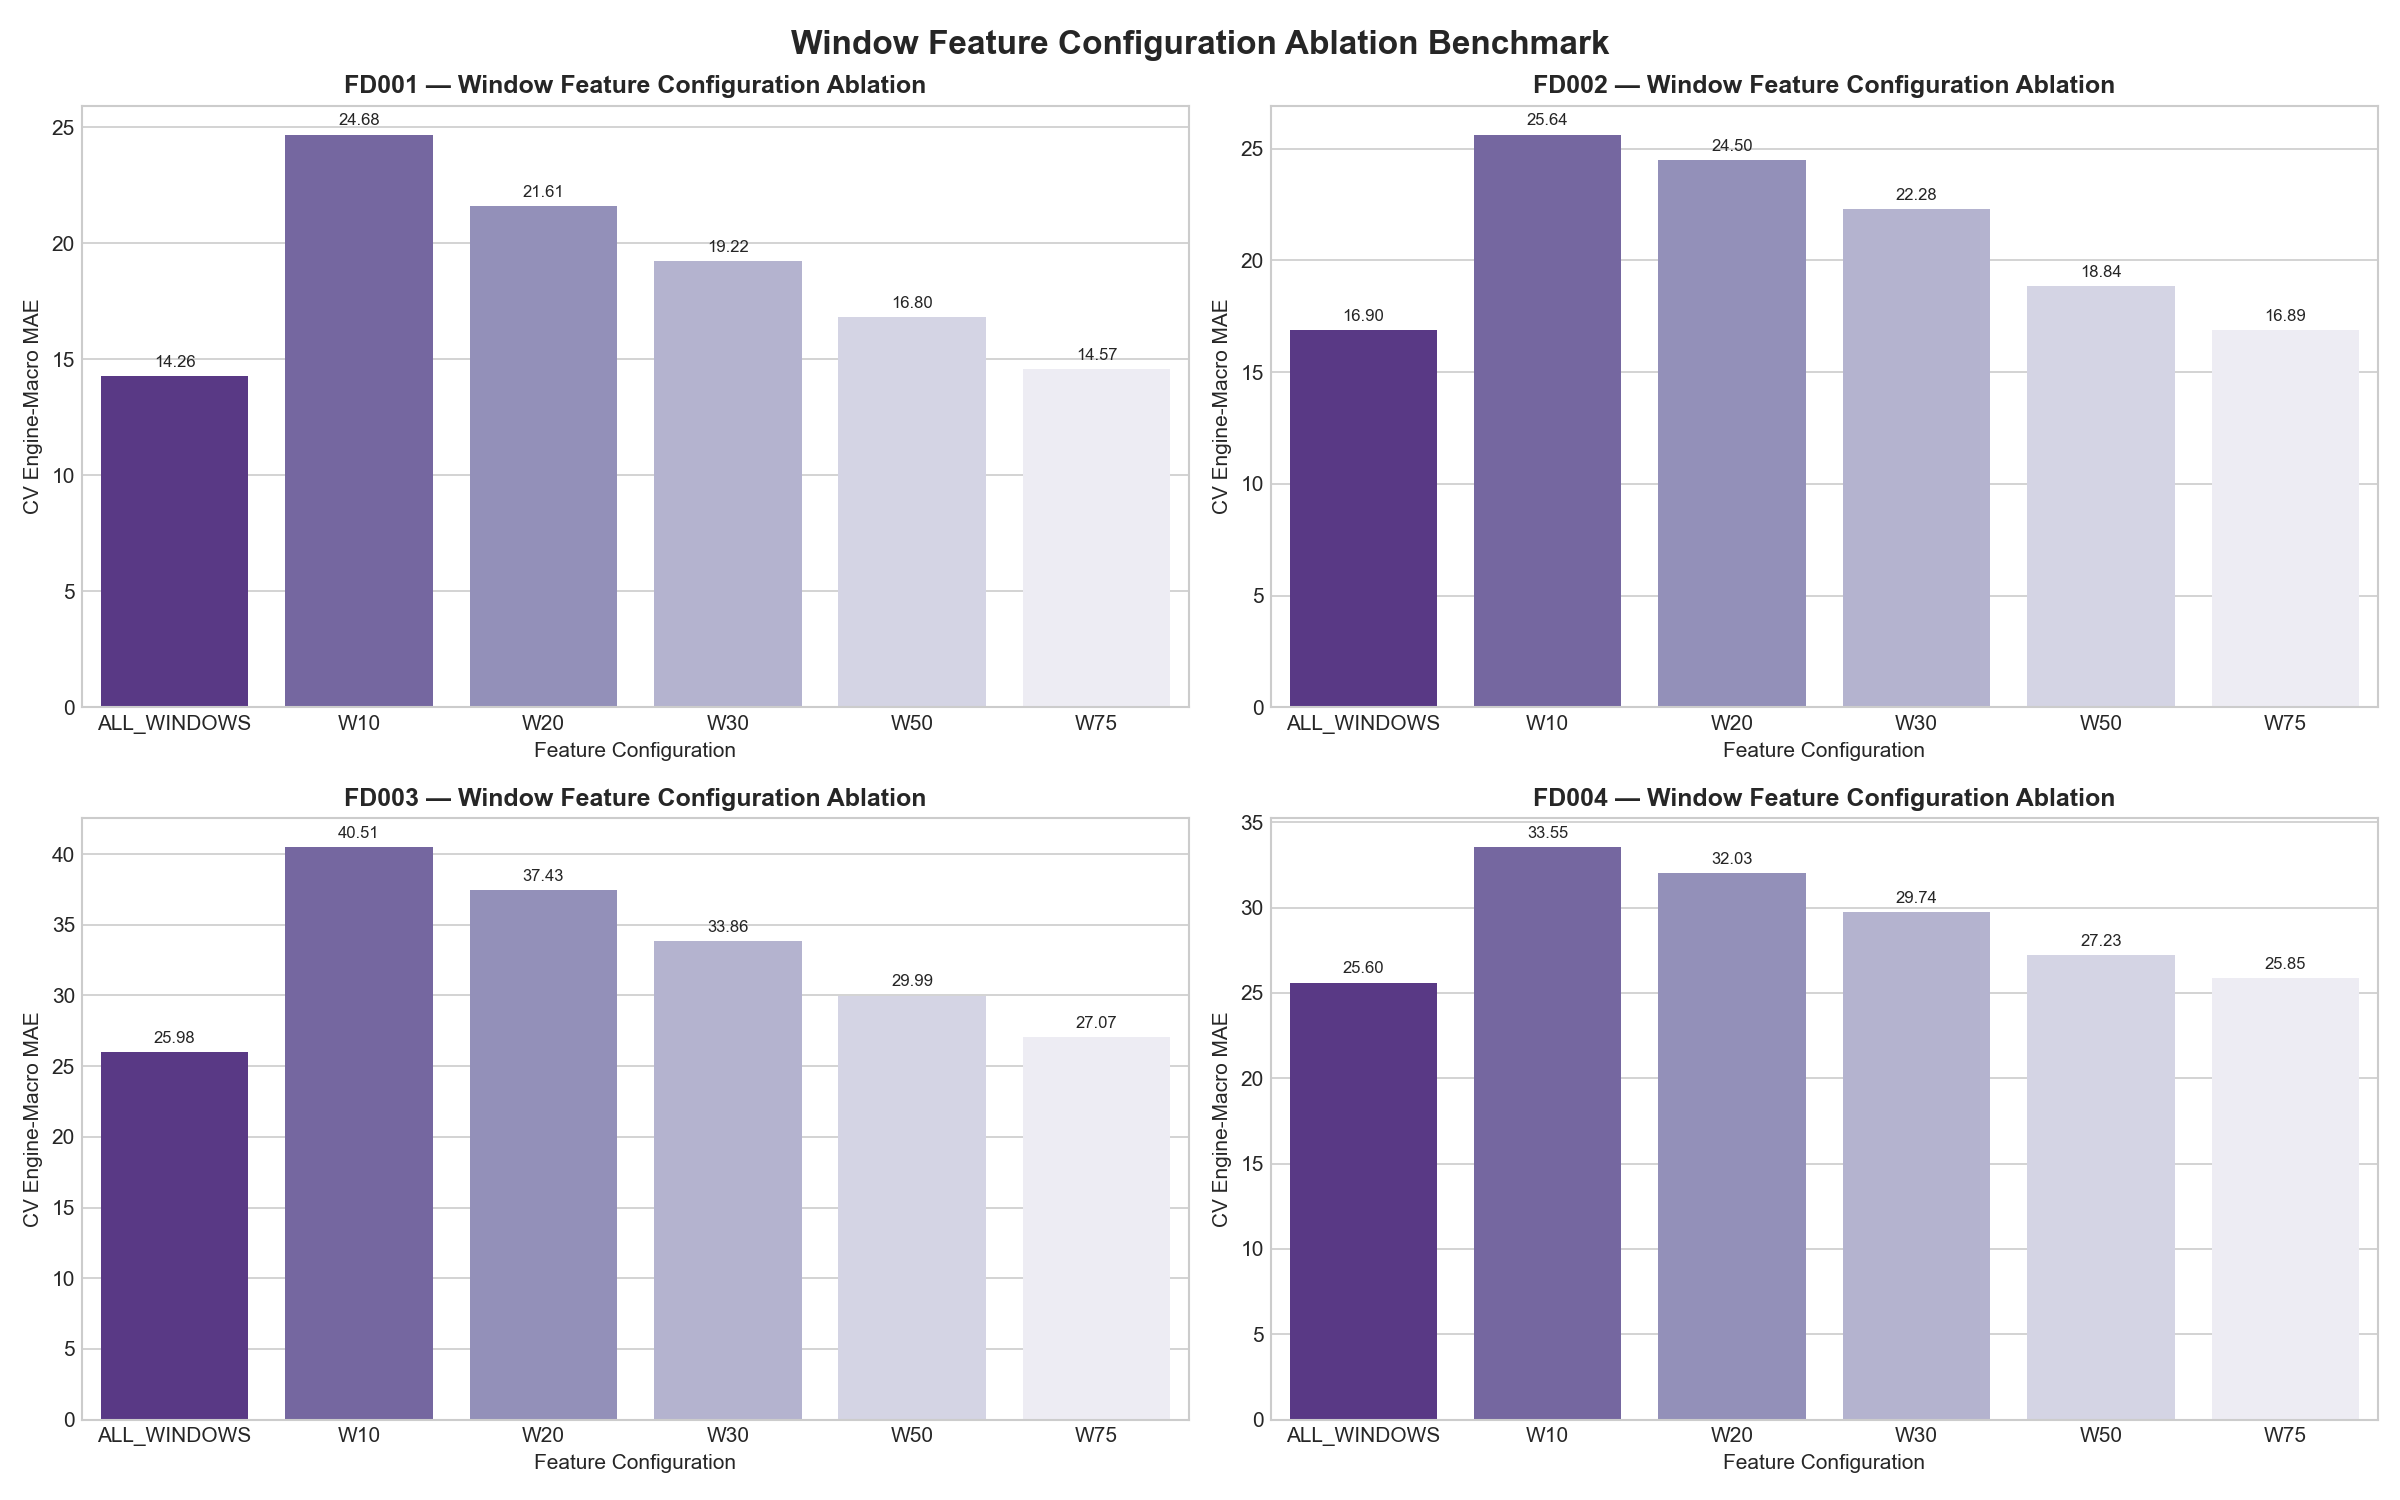

In [6]:
win_df = pd.read_csv(PHASE5_DIR / "window_ablation_metrics.csv")
display(win_df[["dataset", "window_configuration", "feature_count", "cv_engine_macro_mae", "val_engine_macro_mae", "val_pooled_rmse"]])

fig_path = PHASE5_FIGURES_DIR / "window_ablation_comparison.png"
if fig_path.exists():
    from IPython.display import Image
    display(Image(filename=str(fig_path)))

## 7. Configuration Freeze & Final Model Manifest

Before loading official C-MAPSS test labels, the winning configuration for each dataset was frozen in `final_model_manifest.json`.

In [7]:
manifest_file = PHASE5_DIR / "final_model_manifest.json"
with open(manifest_file, "r", encoding="utf-8") as f:
    manifest = json.load(f)

print(f"Manifest Version: {manifest['manifest_version']}")
print(f"Frozen Timestamp: {manifest['frozen_timestamp']}")
print(f"Python: {manifest['system_metadata']['python_version']}")
print(f"Platform: {manifest['system_metadata']['platform']}")

print("\nSelected Configurations per Dataset:")
for subset, cfg in manifest["selected_configurations"].items():
    print(f"\n--- {subset} ---")
    print(f"  Model Family: {cfg['model_family']}")
    print(f"  Target Cap: {cfg['target_cap']}")
    print(f"  Feature Config: {cfg['feature_configuration']} ({cfg['n_features']} features)")
    print(f"  Inner-CV Engine-Macro MAE: {cfg['inner_cv_scores']['engine_macro_mae']:.2f}")
    print(f"  Dev-Val Macro MAE: {cfg['development_validation_scores']['engine_macro_mae']:.2f}")

Manifest Version: 1.0
Frozen Timestamp: 2026-10-27 00:35:50
Python: 3.11.2
Platform: win32

Selected Configurations per Dataset:

--- FD001 ---
  Model Family: LightGBM
  Target Cap: 150
  Feature Config: ALL_WINDOWS (670 features)
  Inner-CV Engine-Macro MAE: 14.26
  Dev-Val Macro MAE: 11.72

--- FD002 ---
  Model Family: LightGBM
  Target Cap: 150
  Feature Config: W75 (231 features)
  Inner-CV Engine-Macro MAE: 16.90
  Dev-Val Macro MAE: 16.65

--- FD003 ---
  Model Family: LightGBM
  Target Cap: None
  Feature Config: ALL_WINDOWS (681 features)
  Inner-CV Engine-Macro MAE: 25.98
  Dev-Val Macro MAE: 21.60

--- FD004 ---
  Model Family: LightGBM
  Target Cap: None
  Feature Config: ALL_WINDOWS (768 features)
  Inner-CV Engine-Macro MAE: 25.60
  Dev-Val Macro MAE: 27.63


## 8. Stage C: Official C-MAPSS Test Set Evaluation

Final frozen models were evaluated once on each test engine's last recorded cycle against official ground truth remaining life (`RUL_FD*.txt`).

Official C-MAPSS Test Metrics:

,dataset,selected_model,selected_feature_configuration,selected_target_cap,endpoint_mae,endpoint_rmse,endpoint_r2,mean_signed_error,underprediction_count,overprediction_count,nasa_score_sum,nasa_score_mean,n_official_test_engines,n_successfully_predicted
0,FD001,LightGBM,ALL_WINDOWS,150.0,11.434757,15.685765,0.857521,4.074434,44,56,5.898683e+02,5.898683,100,100
1,FD002,LightGBM,W75,150.0,13.783750,20.127055,0.859932,-1.218151,135,124,2.306695e+03,8.906159,259,259
2,FD003,LightGBM,ALL_WINDOWS,NaN,14.680725,25.002669,0.635192,11.582277,27,73,6.697540e+04,669.754017,100,100
3,FD004,LightGBM,ALL_WINDOWS,NaN,22.812514,33.801785,0.615667,11.638342,95,153,1.139046e+06,4592.929280,248,248



Total Test Predictions: 707


,dataset,unit_id,last_observed_cycle,actual_rul_official,predicted_rul_raw,predicted_rul_final,prediction_error,absolute_error,selected_model,selected_feature_configuration,selected_target_cap
0,FD001,1,31,112.0,143.064411,143.064411,31.064411,31.064411,LightGBM,ALL_WINDOWS,150.0
1,FD001,2,49,98.0,138.354083,138.354083,40.354083,40.354083,LightGBM,ALL_WINDOWS,150.0
2,FD001,3,126,69.0,49.819627,49.819627,-19.180373,19.180373,LightGBM,ALL_WINDOWS,150.0
3,FD001,4,106,82.0,86.622231,86.622231,4.622231,4.622231,LightGBM,ALL_WINDOWS,150.0
4,FD001,5,98,91.0,101.390261,101.390261,10.390261,10.390261,LightGBM,ALL_WINDOWS,150.0
5,FD001,6,105,93.0,125.028937,125.028937,32.028937,32.028937,LightGBM,ALL_WINDOWS,150.0
6,FD001,7,160,91.0,87.784982,87.784982,-3.215018,3.215018,LightGBM,ALL_WINDOWS,150.0
7,FD001,8,166,95.0,110.283815,110.283815,15.283815,15.283815,LightGBM,ALL_WINDOWS,150.0
8,FD001,9,55,111.0,129.537884,129.537884,18.537884,18.537884,LightGBM,ALL_WINDOWS,150.0
9,FD001,10,192,96.0,79.939095,79.939095,-16.060905,16.060905,LightGBM,ALL_WINDOWS,150.0


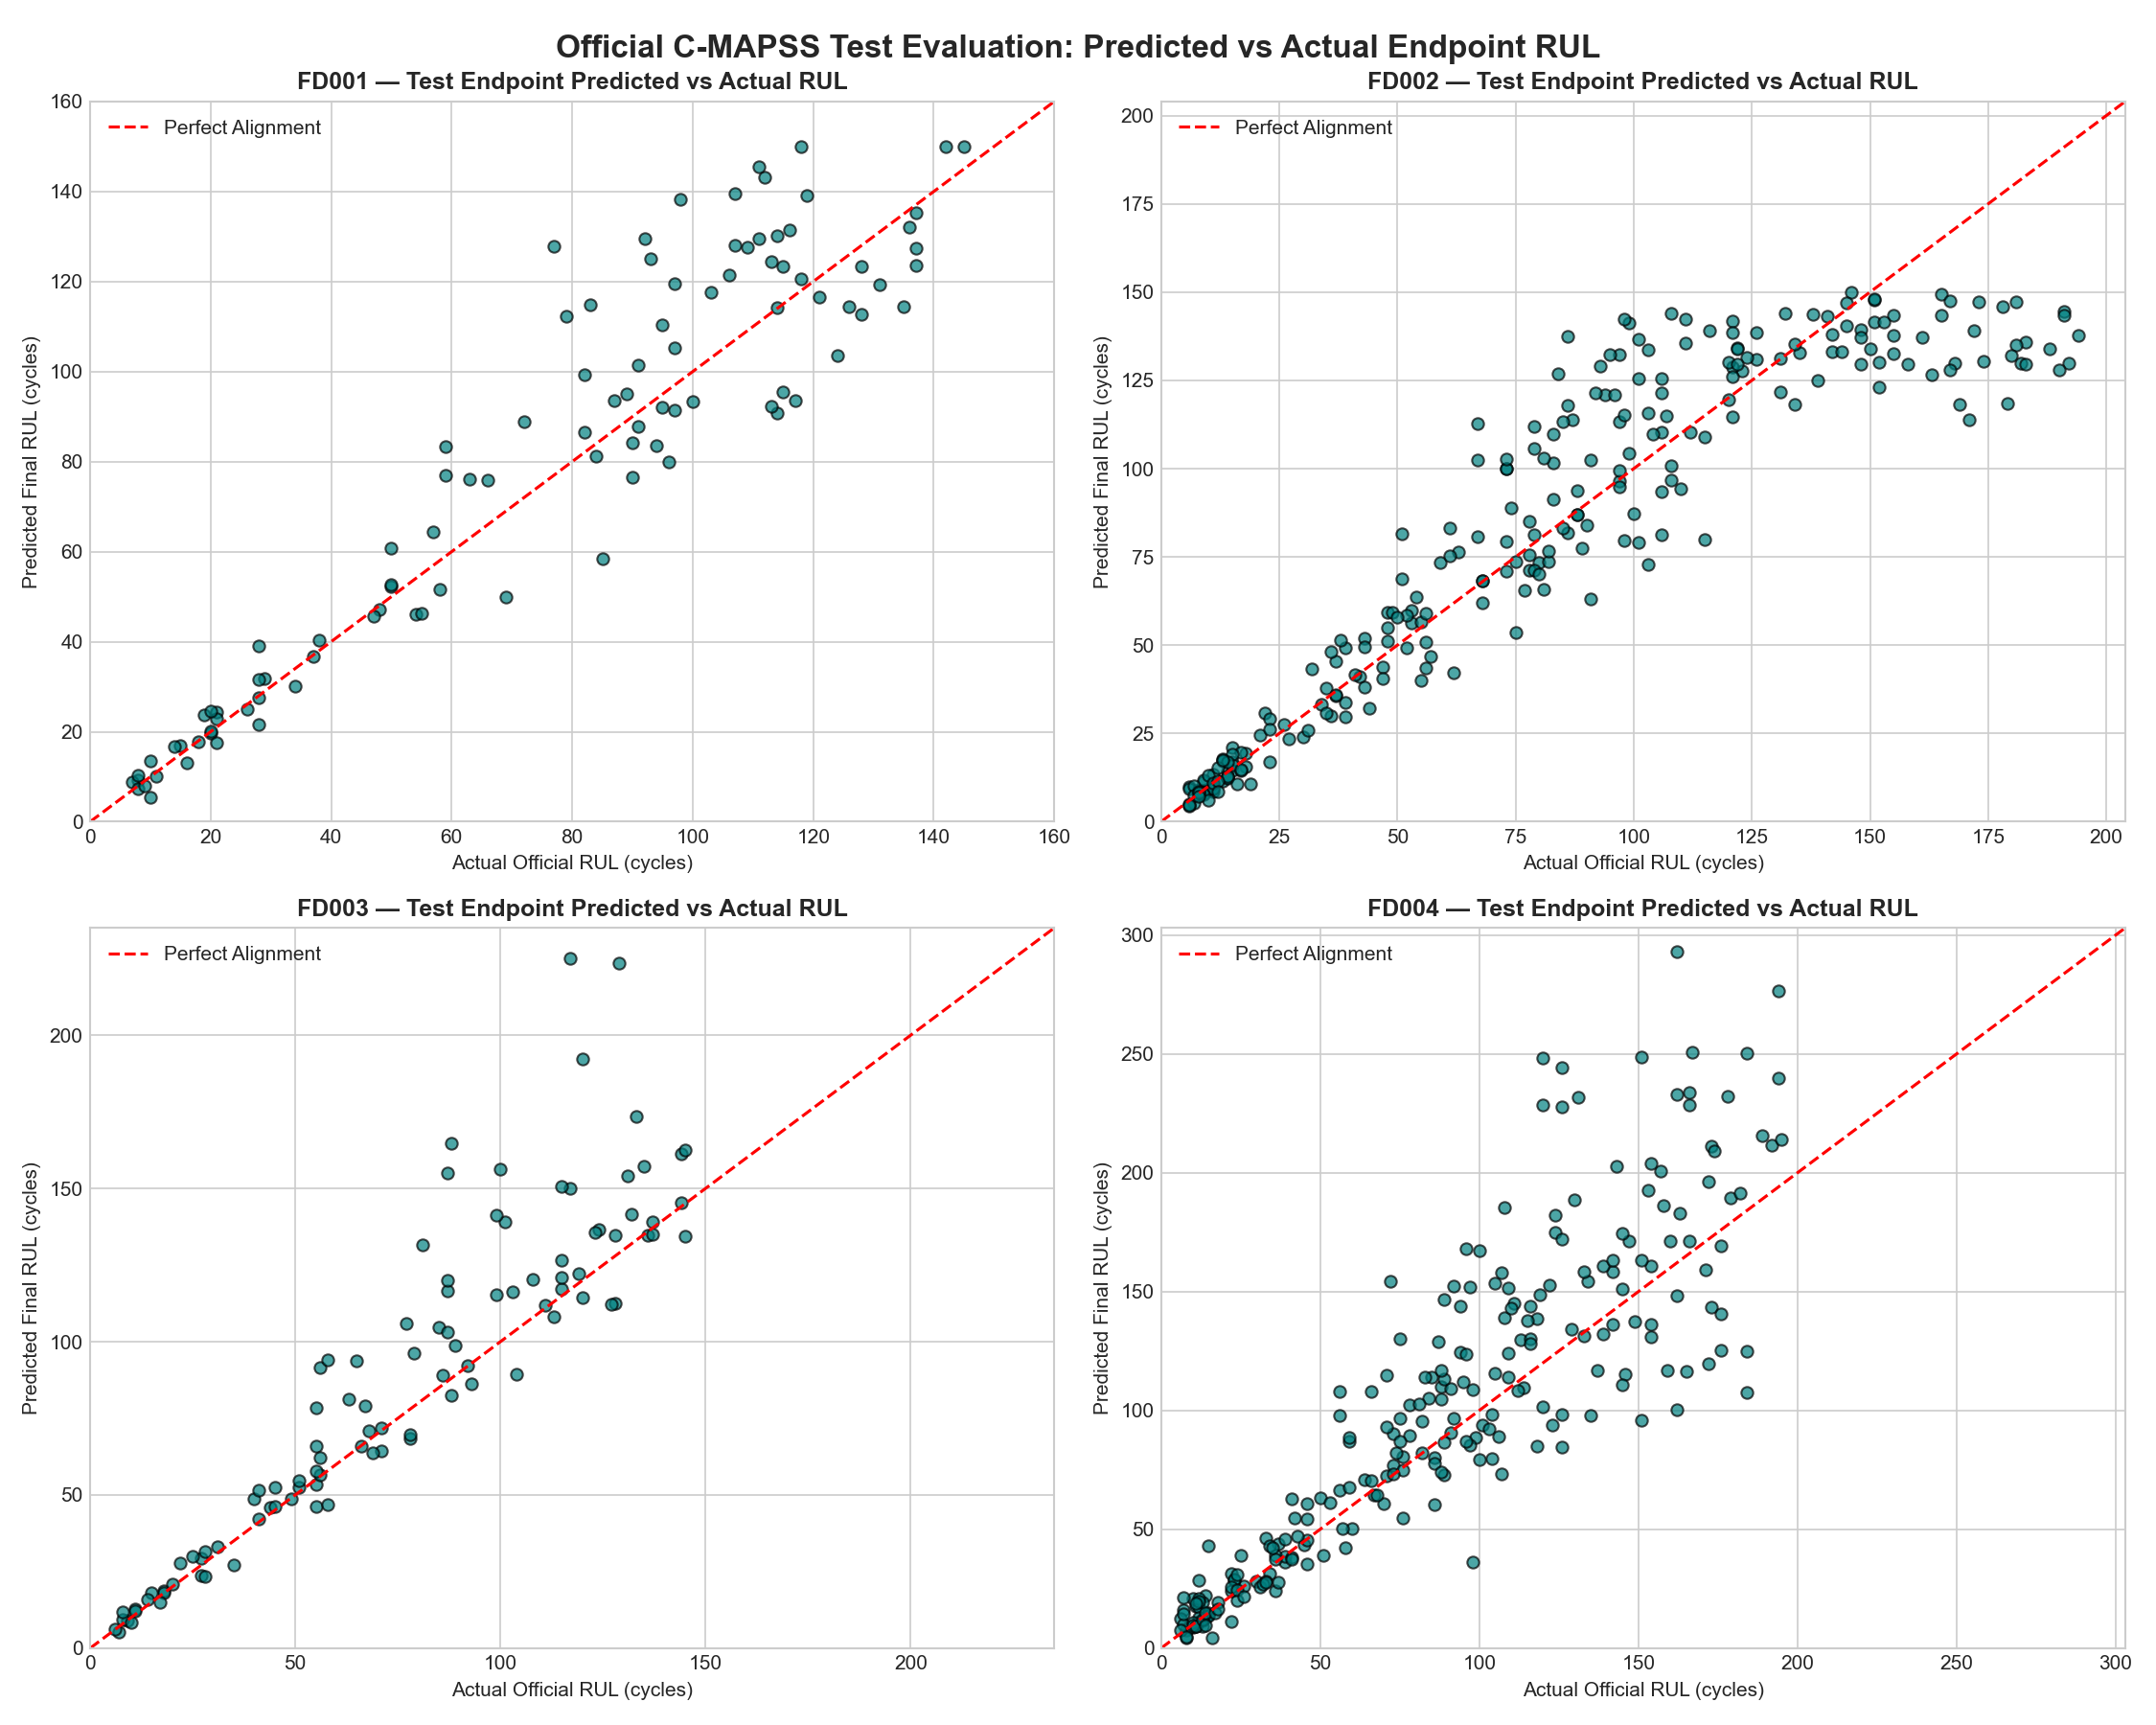

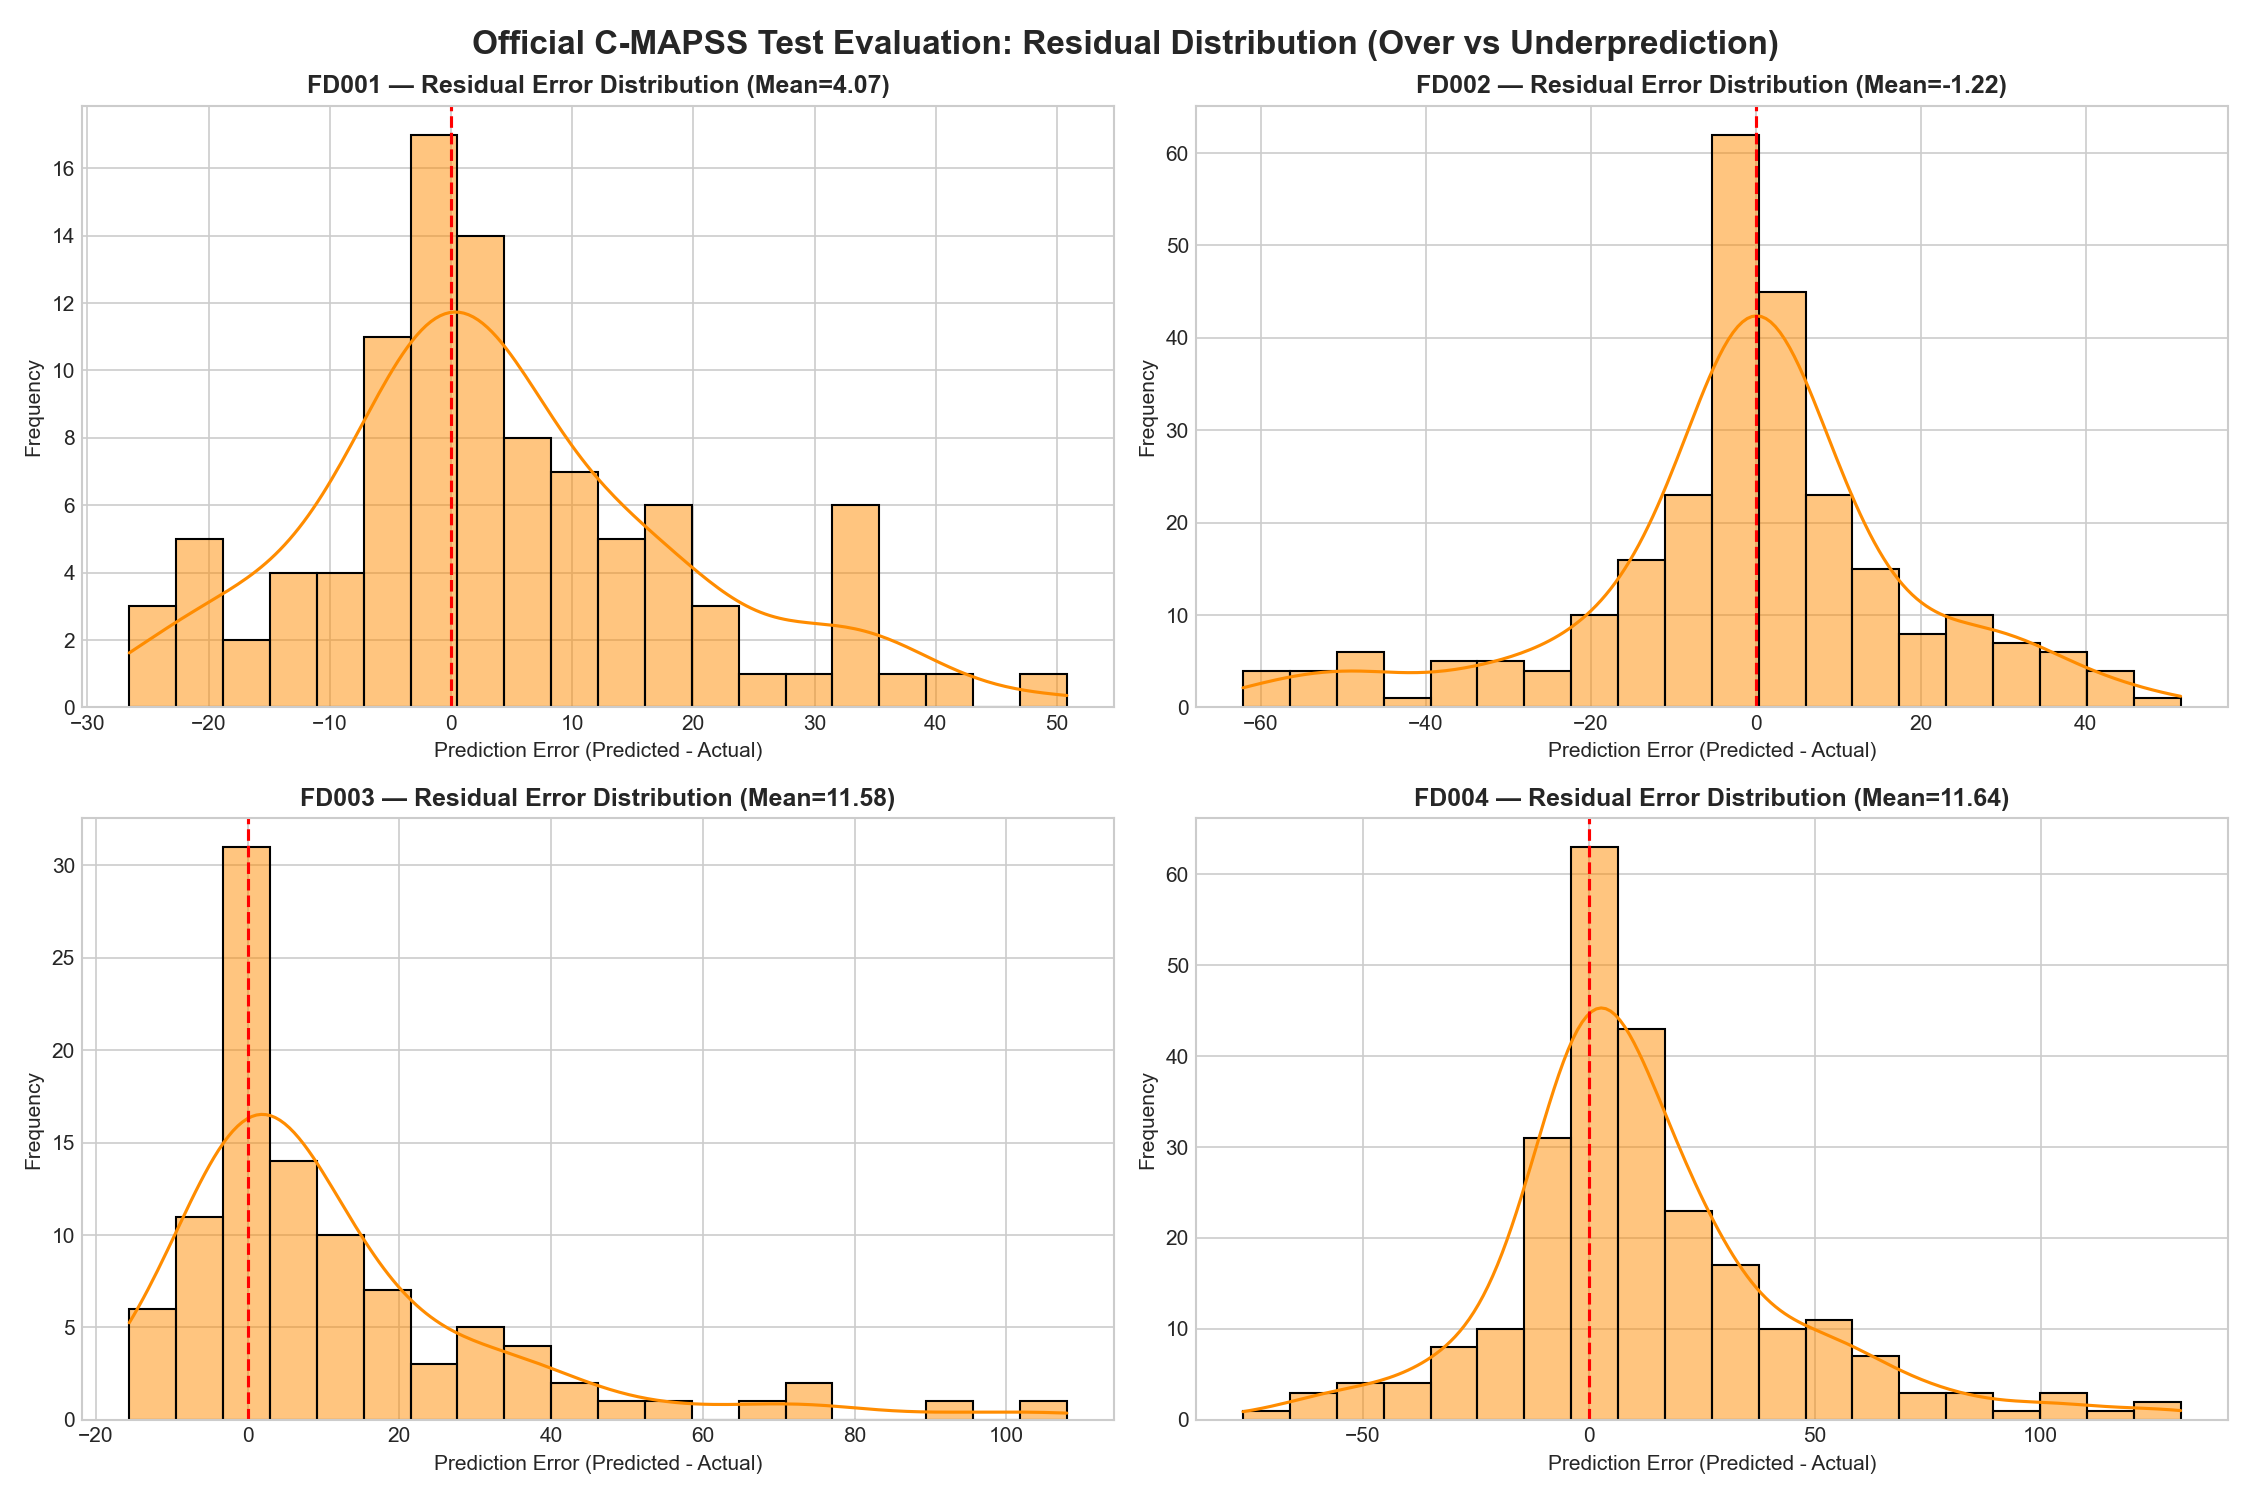

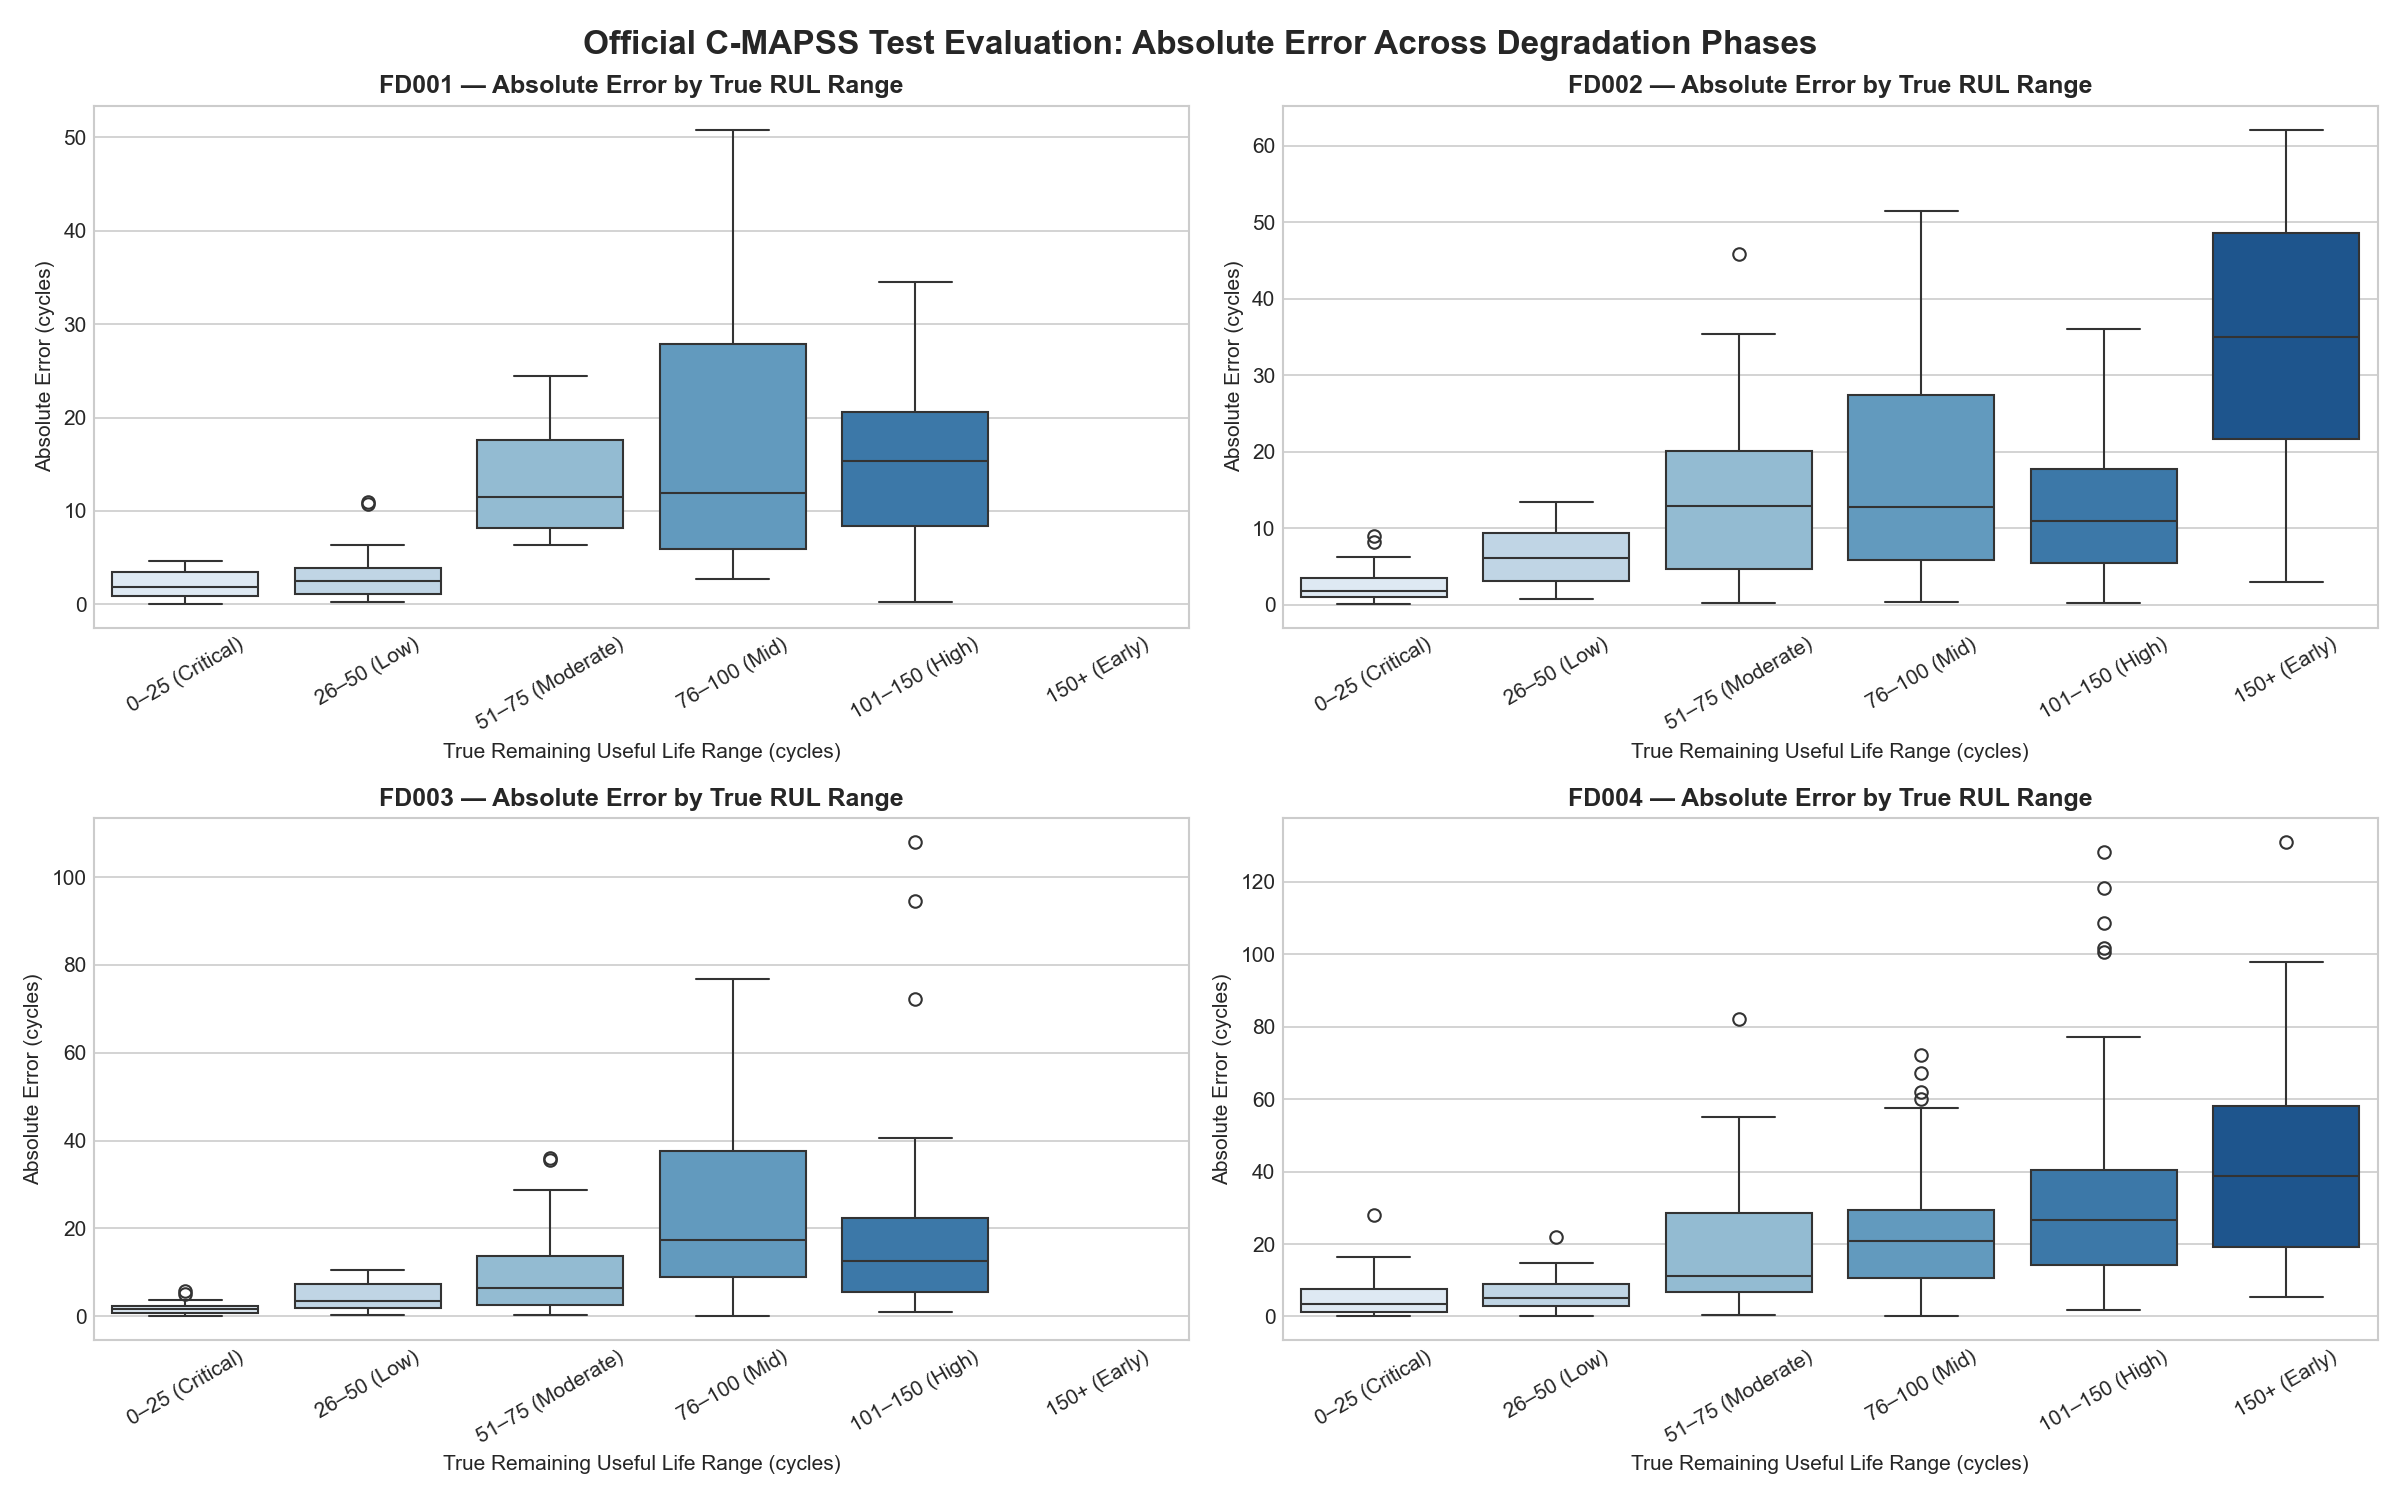

In [8]:
test_metrics_df = pd.read_csv(PHASE5_DIR / "final_test_metrics.csv")
test_preds_df = pd.read_csv(PHASE5_DIR / "final_test_predictions.csv")

print("Official C-MAPSS Test Metrics:")
display(test_metrics_df)

print(f"\nTotal Test Predictions: {len(test_preds_df)}")
display(test_preds_df.head(10))

# Display diagnostic figures
for fig_name in [
    "final_test_predicted_vs_actual.png",
    "final_test_residuals.png",
    "final_test_error_by_rul_range.png",
]:
    fig_path = PHASE5_FIGURES_DIR / fig_name
    if fig_path.exists():
        from IPython.display import Image
        display(Image(filename=str(fig_path)))

## 9. Metric Integrity & Verification Checks

Independently recomputing all official test metrics directly from saved prediction rows to guarantee 100% mathematical integrity.

In [9]:
for _, row in test_metrics_df.iterrows():
    subset = row["dataset"]
    sub_p = test_preds_df[test_preds_df["dataset"] == subset]
    y_true = sub_p["actual_rul_official"].values
    y_pred = sub_p["predicted_rul_final"].values

    calc_mae = mae(y_true, y_pred)
    calc_rmse = rmse(y_true, y_pred)
    calc_nasa_sum = nasa_score(y_true, y_pred)

    assert np.isclose(calc_mae, row["endpoint_mae"], atol=1e-2), f"{subset} MAE mismatch!"
    assert np.isclose(calc_rmse, row["endpoint_rmse"], atol=1e-2), f"{subset} RMSE mismatch!"
    assert np.isclose(calc_nasa_sum, row["nasa_score_sum"], atol=1.0), f"{subset} NASA mismatch!"
    print(f"✓ {subset} verified: MAE={calc_mae:.2f}, RMSE={calc_rmse:.2f}, NASA Sum={calc_nasa_sum:.1f}")

print("\nAll official test results independently verified and reconciled!")

✓ FD001 verified: MAE=11.43, RMSE=15.69, NASA Sum=589.9


✓ FD002 verified: MAE=13.78, RMSE=20.13, NASA Sum=2306.7
✓ FD003 verified: MAE=14.68, RMSE=25.00, NASA Sum=66975.4
✓ FD004 verified: MAE=22.81, RMSE=33.80, NASA Sum=1139046.5

All official test results independently verified and reconciled!
